# Rotationskurven und Dunkle Materie

Das Notebook lädt die SPARC-Datenbank (175 Scheibengalaxien mit Spitzer-Photometrie bei 3.6 µm und Rotationskurven aus HI- und Hα-Messungen), zerlegt die Rotationskurve einer Galaxie (voreingestellt NGC 2403) in die Beiträge von Gas, Sternscheibe und Bulge und passt zwei Modelle für den Halo aus Dunkler Materie an: ein NFW-Profil aus kosmologischen Simulationen und ein pseudo-isothermes Profil mit flachem Kern. Über alle Galaxien bestimmt es die radiale Beschleunigungsrelation und die baryonische Tully-Fisher-Beziehung und vergleicht beide mit den Veröffentlichungen des SPARC-Teams.

Wie viel Masse fehlt in Scheibengalaxien, wenn man nur Sterne und Gas zählt, und wie ist die fehlende Masse verteilt?

#### **Hintergrund**

Rotationskurven sind der klassische Hinweis auf Dunkle Materie. Sterne und Gas in einer Scheibengalaxie laufen auf fast kreisförmigen Bahnen um das Zentrum, und die Geschwindigkeit, die eine Bahn braucht, hängt nur von der Masse ab, die sie anzieht. Misst man die Rotationsgeschwindigkeit in verschiedenen Abständen vom Zentrum, wiegt man die Galaxie. Seit den 1970er Jahren zeigen solche Messungen (Rubin, Ford & Thonnard 1980; Bosma 1981): Die Kurven bleiben außen flach, statt wie bei den Planeten um die Sonne abzufallen. Weit außen muss es also Masse geben, die man nicht sieht. Nach dem kosmologischen Standardmodell ist das Dunkle Materie, die einen ausgedehnten Halo um jede Galaxie bildet und insgesamt etwa fünfmal so viel Masse hat wie die gewöhnliche Materie.

Zwei Fragen sind bis heute offen, und Rotationskurven sind die wichtigsten Daten dafür. Erstens die Form des Halos: Simulationen mit kalter Dunkler Materie sagen eine Dichte voraus, die zum Zentrum hin steil ansteigt, viele Zwerggalaxien zeigen aber einen flachen Kern. Zweitens die erstaunlich enge Kopplung zwischen sichtbarer und Dunkler Materie: Aus der Verteilung der Sterne und des Gases allein lässt sich die Rotation fast jeder Galaxie mit einer einzigen Formel vorhersagen, was manche als Hinweis auf eine geänderte Schwerkraft (MOND) statt auf Dunkle Materie deuten. Dieses Notebook untersucht beides mit der SPARC-Datenbank aus 175 Galaxien.

Landkarte:

- **Daten**
  - Die SPARC-Datenbank (Schritt 1): 175 Rotationskurven mit 3391 Punkten; NGC 2403 als Beispiel.
- **Reduktion**
  - Qualitätsschnitte (Schritt 2): 2696 Punkte aus 147 Galaxien bleiben.
- **Eigene Messung**
  - Sichtbare Materie gegen Rotation (Schritt 3): Sterne und Gas erklären in NGC 2403 außen nur 15 % der Masse.
- **Modell und Fit**
  - NFW-Halo gegen Halo mit Kern (Schritt 4): Für NGC 2403 passt das Profil aus Simulationen besser.
  - Radiale Beschleunigungsrelation (Schritt 5): Alle Galaxien liegen auf einer Kurve mit $g_\dagger = 1.16\cdot10^{-10}$ m/s².
  - Baryonische Tully-Fisher-Beziehung (Schritt 6): Die sichtbare Masse wächst etwa mit der vierten Potenz der Geschwindigkeit.
- **Eigene Messung gegen den Katalog**
  - Vergleich (Schritt 7): $g_\dagger$, Streuung und Steigung wie in den SPARC-Veröffentlichungen.

Verwandte Notebooks: Bulge und Scheibe einer Galaxie aus Bildern in [Photometrie einer Galaxie](https://github.com/deltorobarba/science/blob/main/astro/galaxies_photometry.ipynb), Verbiegungen der Scheibe in [Warps in Edge-on-Galaxien](https://github.com/deltorobarba/science/blob/main/astro/galaxies_warps.ipynb).

#### **Theorie**

##### *1. Rotationskurven*

Auf einer Kreisbahn liefert die Gravitation die Zentripetalbeschleunigung, $v^2/r = g(r)$. Für eine kugelsymmetrische Massenverteilung ist $g = G M(<r)/r^2$, also
$$v(r) = \sqrt{\frac{G\,M(<r)}{r}} .$$
Liegt fast die ganze Masse innerhalb von $r$, fällt die Geschwindigkeit wie $v\propto r^{-1/2}$ ab (**Kepler-Abfall**), wie bei den Planeten. Für eine dünne Scheibe gilt die Formel nicht genau, weil auch Masse außerhalb von $r$ zieht; SPARC löst dafür die **Poisson-Gleichung** mit der gemessenen Flächendichte.

Die **Rotationskurve** $v(r)$ misst man über den Doppler-Effekt: optisch mit der **Hα-Linie** des ionisierten Gases, im Radiobereich mit der **21-cm-Linie** des neutralen Wasserstoffs (HI). Das HI reicht oft zwei- bis dreimal so weit hinaus wie die Sternscheibe. Gemessen wird nur die Komponente entlang der Sichtlinie; die Rotation folgt nach Division durch $\sin i$ mit der **Neigung** $i$ der Scheibe (90° heißt Kante). Die **Skalenlänge** $R_d$ einer exponentiellen Scheibe ist der Radius, auf dem ihre Flächenhelligkeit auf $1/e$ fällt; bei $2.2\,R_d$ hat die Rotation einer reinen Scheibe ihr Maximum.

##### *2. Sichtbare Materie und Dunkle Materie*

Die Potentiale der Komponenten addieren sich, also auch ihre Beschleunigungen, und mit $v^2 = r\,g$ die Quadrate der Geschwindigkeiten:
$$V_\text{obs}^2 = V_\text{gas}^2 + \Upsilon_\text{disk} V_\text{disk}^2 + \Upsilon_\text{bul} V_\text{bul}^2 + V_\text{DM}^2 .$$
SPARC gibt $V_\text{disk}$ und $V_\text{bul}$ für ein **Masse-Leuchtkraft-Verhältnis** $\Upsilon = 1\,M_\odot/L_\odot$ an; weil $V^2$ proportional zur Masse ist, skaliert man mit $\Upsilon V^2$. Bei 3.6 µm folgt das Licht gut der Sternmasse, und $\Upsilon_\text{disk} = 0.5$, $\Upsilon_\text{bul} = 0.7$ sind übliche Werte aus Modellen der Sternpopulationen. Hat das Gas innen ein Loch, zieht der Gasring dort nach außen; SPARC gibt dann ein negatives $V_\text{gas}$ an, und man rechnet mit $\vert V_\text{gas}\vert V_\text{gas}$. Die sichtbare (**baryonische**) Materie zusammen gibt $V_\text{bar}^2$, und der Anteil der fehlenden Masse innerhalb von $r$ ist (kugelsymmetrisch genähert)
$$f_\text{DM}(r) = 1 - \frac{V_\text{bar}^2(r)}{V_\text{obs}^2(r)} .$$
Wählt man $\Upsilon$ so groß wie möglich, sodass die Sterne die innere Kurve allein erklären, spricht man von einer **maximalen Scheibe**; bei $2.2\,R_d$ liefert sie etwa 85 % der Rotation (Sackett 1997).

##### *3. Halo-Profile*

Simulationen mit kalter Dunkler Materie ergeben das **NFW-Profil** (Navarro, Frenk & White 1996)
$$\rho(r) = \frac{\rho_s}{(r/r_s)(1 + r/r_s)^2} ,$$
innen $\rho\propto r^{-1}$ (ein **Cusp**), außen $\rho\propto r^{-3}$. Den Halo begrenzt man bei $R_{200}$, innerhalb dessen die mittlere Dichte 200-mal die kritische Dichte des Universums ist; dort hat er die Masse $M_{200}$ und die Kreisgeschwindigkeit $V_{200}$, und es gilt $R_{200} = V_{200}/(10 H_0)$. Die **Konzentration** $c = R_{200}/r_s$ sagt, wie stark die Masse zum Zentrum hin gebündelt ist. Die Rotation des Halos ist mit $x = r/R_{200}$
$$V_\text{NFW}^2(r) = V_{200}^2\,\frac{\ln(1+cx) - cx/(1+cx)}{x\,[\ln(1+c) - c/(1+c)]} .$$

Das **pseudo-isotherme Profil** hat dagegen einen flachen **Kern** vom Radius $r_c$:
$$\rho(r) = \frac{\rho_0}{1 + (r/r_c)^2}, \qquad V_\text{iso}^2(r) = V_\infty^2\left[1 - \frac{r_c}{r}\arctan\frac{r}{r_c}\right] .$$
Innen steigt seine Rotation linear an wie bei einem starren Körper, außen wird sie flach mit $V_\infty$. Dass viele Zwerggalaxien einen Kern zeigen, wo die Simulationen einen Cusp vorhersagen, heißt **Core-Cusp-Problem**.

##### *4. Die radiale Beschleunigungsrelation*

Für jeden Punkt jeder Rotationskurve vergleicht man die gemessene Beschleunigung $g_\text{obs} = V_\text{obs}^2/r$ mit der, die die sichtbare Materie allein erzeugt, $g_\text{bar} = V_\text{bar}^2/r$. McGaugh, Lelli & Schombert (2016) beschreiben den Zusammenhang mit
$$g_\text{obs} = \frac{g_\text{bar}}{1 - e^{-\sqrt{g_\text{bar}/g_\dagger}}} .$$
Für $g_\text{bar}\gg g_\dagger$ ist $g_\text{obs}\approx g_\text{bar}$: keine fehlende Masse. Für $g_\text{bar}\ll g_\dagger$ ist $g_\text{obs}\approx\sqrt{g_\text{bar}\,g_\dagger}$. Der Parameter $g_\dagger$, etwa $10^{-10}$ m/s², ist die Beschleunigung, unterhalb der die Dunkle Materie wichtig wird; die Formel ähnelt der von MOND, wo dieselbe Grenze $a_0$ heißt.

##### *5. Die baryonische Tully-Fisher-Beziehung*

Weit außen ist fast alle sichtbare Masse $M_\text{bar}$ eingeschlossen, $g_\text{bar} = G M_\text{bar}/r^2$ ist klein, und mit $g_\text{obs} = V_\text{flat}^2/r$ und der Näherung aus Abschnitt 4 folgt
$$M_\text{bar} = \frac{V_\text{flat}^4}{G\,g_\dagger} .$$
Der Radius fällt heraus: Die Masse wächst mit der vierten Potenz der **flachen Rotationsgeschwindigkeit** $V_\text{flat}$, mit einem Vorfaktor, der durch $g_\dagger$ festgelegt ist (**baryonische Tully-Fisher-Beziehung**). Die Masse setzt sich aus Sternen und Gas zusammen, $M_\text{bar} = \Upsilon_\text{disk} L_{3.6} + 1.33\,M_\text{HI}$; der Faktor 1.33 rechnet das Helium dazu.

##### *6. Fehler und Güte eines Fits*

Eine gewöhnliche Regression von $y$ auf $x$ setzt $x$ als fehlerfrei voraus. Streut $x$ um seinen wahren Wert, wird die Steigung zu flach (**Regression Dilution**). Die **orthogonale Regression** (ODR) minimiert stattdessen die Abstände senkrecht zur Geraden, gewichtet mit den Fehlern in beiden Achsen.

Das **reduzierte χ²** ist die Summe der quadrierten Abweichungen in Einheiten der Fehler, geteilt durch die Zahl der Freiheitsgrade. Werte um 1 heißen, das Modell passt im Rahmen der Fehler; viel größere Werte, dass das Modell etwas nicht beschreibt oder die Fehler zu klein angegeben sind.

#### **Daten**

Von der SPARC-Webseite (`https://astroweb.case.edu/SPARC/`):
- **`SPARC_Lelli2016c.mrt`**, die Tabelle der Galaxien: Hubble-Typ, Entfernung, Neigung, Leuchtkraft bei 3.6 µm, Skalenlänge der Scheibe, HI-Masse, flache Rotationsgeschwindigkeit $V_\text{flat}$ und eine Qualitätsmarke (1 hoch, 2 mittel, 3 niedrig).
- **`Rotmod_LTG.zip`**, eine Datei pro Galaxie: Radius, beobachtete Geschwindigkeit mit Fehler (schon um die Neigung korrigiert) und die Geschwindigkeiten, die Gas, Scheibe und Bulge allein erzeugen würden ($\Upsilon = 1$).

Beide Dateien (zusammen etwa 200 kB) landen in `astrodata/sparc`; mit `REFRESH = True` lädt das Notebook sie neu.

**Hintergrund & Fachbegriffe:**
- **SPARC:** Spitzer Photometry and Accurate Rotation Curves (Lelli, McGaugh & Schombert 2016), Rotationskurven aus der Literatur, verbunden mit Bildern des Spitzer-Weltraumteleskops bei 3.6 µm.
- **Hubble-Typ:** die Form der Galaxie, von S0 (linsenförmig, ohne Arme) über Sa bis Sd (immer lockerere Arme, kleinerer Bulge) bis Im (irregulär) und BCD (kompakte blaue Zwerge).
- **NGC 2403:** eine Spirale vom Typ Scd in 3.2 Mpc Entfernung mit einer weit ausgedehnten HI-Scheibe, voreingestellt.

In [1]:
# In Colab fehlt astroquery (nur für die Übersetzung von Namen wie "M 63"); lokal ist es meist schon installiert
import importlib.util, subprocess, sys
if importlib.util.find_spec("astroquery") is None:
    if "google.colab" not in sys.modules:       # lokal nichts automatisch installieren: pip würde numpy mit aktualisieren
        raise ImportError("Es fehlt astroquery; bitte lokal selbst installieren, am besten mit conda (conda-forge), "
                          "damit numpy und die übrigen Pakete unverändert bleiben")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "astroquery"], check=True)

In [2]:
import io
import os
import zipfile
import urllib.request
from pathlib import Path

ASTRODATA = Path.cwd() / "astrodata"
(ASTRODATA / "astropy").mkdir(parents=True, exist_ok=True)
(ASTRODATA / "sparc").mkdir(parents=True, exist_ok=True)
os.environ["XDG_CACHE_HOME"] = str(ASTRODATA)       # vor dem ersten Import von astropy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy import odr
from astroquery.simbad import Simbad

GALAXY = "NGC 2403"        # SPARC-Name oder SIMBAD-Name, z. B. "M 63" (= NGC 5055), "DDO 154", "UGC 128"
REFRESH = False            # True: SPARC-Dateien neu laden
SPARC_URL = "https://astroweb.case.edu/SPARC/"
UPS_DISK, UPS_BUL = 0.5, 0.7   # Masse-Leuchtkraft-Verhältnisse bei 3.6 µm [M_sun/L_sun]
H0_KPC = 73 / 1000             # H0 = 73 km/s/Mpc in km/s/kpc (Entfernungsskala von SPARC)
G_KPC = 4.30091e-6             # Gravitationskonstante [kpc (km/s)² / M_sun]
ACC = 1e6 / 3.0857e19          # (km/s)²/kpc -> m/s²
pd.set_option("display.width", 160)

##### *1. Die SPARC-Datenbank*

Welche Galaxien enthält SPARC, und wie sehen ihre Rotationskurven aus, bevor man irgendetwas modelliert? Vorher vorhersagen: Fallen die Kurven außen ab wie bei den Planeten?

Die Galaxientabelle und die Rotationskurven werden eingelesen, der Name der gewählten Galaxie (auch über SIMBAD-Aliasse wie „M 63“) in den SPARC-Namen übersetzt. Gezeichnet werden alle Kurven gegen den Radius in kpc und gegen den Radius in Skalenlängen der Scheibe, NGC 2403 rot hervorgehoben (Theorie, Abschnitt 1).

**Hintergrund & Fachbegriffe:**
- **kpc:** Kiloparsec, 3260 Lichtjahre; die Sonne ist 8 kpc vom Zentrum der Milchstraße entfernt.
- **$V_\text{flat}$:** die Rotationsgeschwindigkeit im flachen äußeren Teil der Kurve.
- **Qualitätsmarke:** 1 für symmetrische, gut gemessene Kurven, 3 für Kurven mit starken Asymmetrien oder nicht-kreisförmigen Bewegungen.

SPARC: 175 Galaxien, 3,391 Punkte auf den Rotationskurven
Hubble-Typen: {'Im': 39, 'Sm': 27, 'Sbc': 18, 'Sd': 16, 'Sc': 16, 'Scd': 16, 'Sb': 12, 'Sab': 10, 'Sdm': 10, 'BCD': 5, 'S0': 3, 'Sa': 3}
V_flat von 19 bis 332 km/s, Entfernungen von 1.0 bis 128 Mpc

NGC 2403 = NGC2403: Typ Scd, D = 3.16 ± 0.16 Mpc, Neigung 63° ± 3°, L[3.6] = 10.0·10⁹ L_sun, M_HI = 3.20·10⁹ M_sun, Skalenlänge 1.39 kpc, V_flat = 131 ± 5 km/s, Qualität 1
73 Punkte von 0.16 bis 20.9 kpc (= 15.0 Skalenlängen)


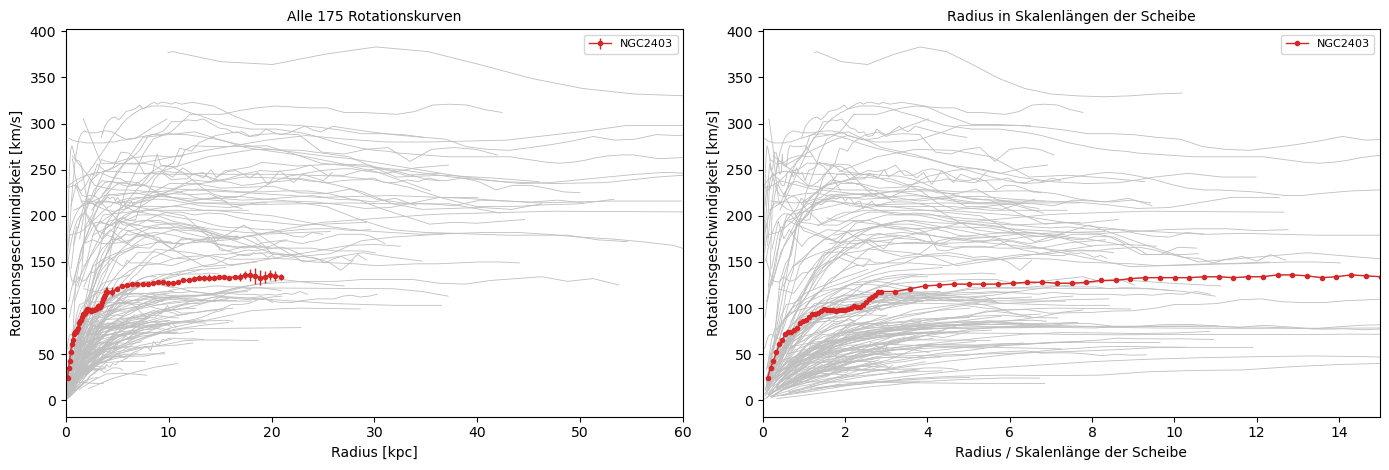

In [3]:
def sparc_file(name):
    path = ASTRODATA / "sparc" / name
    if REFRESH or not path.exists():
        urllib.request.urlretrieve(SPARC_URL + name, path)
    return path

# Galaxientabelle: der Datenblock folgt auf die letzte gestrichelte Linie, die Felder enthalten keine Leerzeichen
mrt = sparc_file("SPARC_Lelli2016c.mrt").read_text()
SPARC_COLS = ["Galaxy", "T", "D", "e_D", "f_D", "Inc", "e_Inc", "L36", "e_L36", "Reff", "SBeff",
              "Rdisk", "SBdisk", "MHI", "RHI", "Vflat", "e_Vflat", "Q", "Ref"]
sparc = pd.read_csv(io.StringIO(mrt.split("-" * 80)[-1].strip()), sep=r"\s+", names=SPARC_COLS)
with zipfile.ZipFile(sparc_file("Rotmod_LTG.zip")) as zf:
    rotmod = {fn.replace("_rotmod.dat", ""): pd.DataFrame(np.loadtxt(zf.open(fn), comments="#"),
                                                          columns=["R", "Vobs", "errV", "Vgas", "Vdisk", "Vbul", "SBdisk", "SBbul"])
              for fn in zf.namelist()}

def sparc_name(name):
    # "NGC 2403" -> "NGC2403", "UGC 128" -> "UGC00128"; sonst die Aliasse aus SIMBAD durchsuchen ("M 63" -> "NGC5055")
    def norm(alias):
        cat, _, num = alias.partition(" ")
        num = num.strip()
        if not num.isdigit():
            return alias.replace(" ", "")
        width = {"NGC": 4, "IC": 4, "UGC": 5, "DDO": 3}.get(cat, 0)
        return f"{cat}{int(num):0{width}d}"
    if norm(name) in rotmod:
        return norm(name)
    ids = Simbad.query_tap(f'''SELECT i2.id FROM ident AS i1 JOIN ident AS i2 ON i1.oidref = i2.oidref
                              WHERE i1.id = '{name}' ''').to_pandas()["id"].str.replace(r"\s+", " ", regex=True)
    return next((norm(a) for a in ids if norm(a) in rotmod), None)

SPARC_GALAXY = sparc_name(GALAXY)
if SPARC_GALAXY is None:
    raise ValueError(f"{GALAXY} ist nicht in SPARC")
props = sparc.loc[sparc["Galaxy"] == SPARC_GALAXY].iloc[0]
rc = rotmod[SPARC_GALAXY]

HUBBLE = ["S0", "Sa", "Sab", "Sb", "Sbc", "Sc", "Scd", "Sd", "Sdm", "Sm", "Im", "BCD"]
print(f"SPARC: {len(sparc)} Galaxien, {sum(len(v) for v in rotmod.values()):,} Punkte auf den Rotationskurven")
print(f"Hubble-Typen: {pd.Series(sparc['T']).map(dict(enumerate(HUBBLE))).value_counts().to_dict()}")
print(f"V_flat von {sparc.loc[sparc['Vflat'] > 0, 'Vflat'].min():.0f} bis {sparc['Vflat'].max():.0f} km/s, "
      f"Entfernungen von {sparc['D'].min():.1f} bis {sparc['D'].max():.0f} Mpc")
print(f"\n{GALAXY} = {SPARC_GALAXY}: Typ {HUBBLE[int(props['T'])]}, D = {props['D']:.2f} ± {props['e_D']:.2f} Mpc, "
      f"Neigung {props['Inc']:.0f}° ± {props['e_Inc']:.0f}°, L[3.6] = {props['L36']:.1f}·10⁹ L_sun, "
      f"M_HI = {props['MHI']:.2f}·10⁹ M_sun, Skalenlänge {props['Rdisk']:.2f} kpc, V_flat = {props['Vflat']:.0f} ± {props['e_Vflat']:.0f} km/s, "
      f"Qualität {props['Q']}")
print(f"{len(rc)} Punkte von {rc['R'].min():.2f} bis {rc['R'].max():.1f} kpc (= {rc['R'].max() / props['Rdisk']:.1f} Skalenlängen)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for name, d in rotmod.items():
    axes[0].plot(d["R"], d["Vobs"], c="0.75", lw=0.6)
    rd = sparc.loc[sparc["Galaxy"] == name, "Rdisk"].iloc[0]
    axes[1].plot(d["R"] / rd, d["Vobs"], c="0.75", lw=0.6)
axes[0].errorbar(rc["R"], rc["Vobs"], rc["errV"], fmt="o-", c="tab:red", ms=3, lw=1, label=SPARC_GALAXY)
axes[1].plot(rc["R"] / props["Rdisk"], rc["Vobs"], "o-", c="tab:red", ms=3, lw=1, label=SPARC_GALAXY)
axes[0].set_xlim(0, 60)
axes[0].set_xlabel("Radius [kpc]")
axes[1].set_xlim(0, 15)
axes[1].set_xlabel("Radius / Skalenlänge der Scheibe")
for ax in axes:
    ax.set_ylabel("Rotationsgeschwindigkeit [km/s]")
    ax.legend(fontsize=8)
axes[0].set_title(f"Alle {len(rotmod)} Rotationskurven", fontsize=10)
axes[1].set_title("Radius in Skalenlängen der Scheibe", fontsize=10)
fig.tight_layout()
plt.show()

* Die **Ausgabe** beschreibt die Stichprobe: 175 Galaxien mit 3391 Punkten, am häufigsten irreguläre Zwerge (Im) und Magellansche Spiralen (Sm), $V_\text{flat}$ von 19 bis 332 km/s, Entfernungen von 1 bis 128 Mpc. NGC 2403 ist eine Scd-Spirale in 3.16 Mpc mit 63° Neigung und einer Kurve aus 73 Punkten bis 20.9 kpc, das sind 15 Skalenlängen: Das HI reicht weit über die Sterne hinaus.
* Das **linke Bild** zeigt alle Kurven (grau) gegen den Radius: Sie steigen innen an und bleiben dann flach, bei 20 bis 330 km/s; kaum eine fällt außen ab, wie es ohne Dunkle Materie zu erwarten wäre. NGC 2403 (rot) steigt bis etwa 5 kpc auf 120 km/s und bleibt dann bei etwa 130 km/s.
* Das **rechte Bild** zeigt dieselben Kurven gegen den Radius in Skalenlängen: Schnell rotierende Galaxien erreichen ihr Plateau schon nach ein bis zwei Skalenlängen, langsame Zwerge steigen oft bis zum letzten Punkt weiter an.

#### **Reduktion**

##### *2. Qualitätsschnitte*

Welche Punkte sind für die Relationen über alle Galaxien gut genug? Vorher vorhersagen: Welcher Schnitt entfernt die meisten Punkte?

Behalten werden nur Galaxien der Qualität 1 oder 2, mit einer Neigung ab 30° (bei kleiner Neigung wird die Korrektur $1/\sin i$ groß und unsicher) und Punkte mit einem Fehler unter 10 % der Geschwindigkeit, wie bei McGaugh, Lelli & Schombert (2016).

**Hintergrund & Fachbegriffe:**
- **Neigungskorrektur:** Bei 30° Neigung multipliziert $1/\sin i$ jede gemessene Geschwindigkeit mit 2, und ein Fehler der Neigung von 5° ändert das Ergebnis um 15 %.
- **Relativer Fehler:** der Fehler geteilt durch die Geschwindigkeit; innen, wo die Rotation langsam ist, ist er oft groß.

alle                          3391 Punkte aus 175 Galaxien
Qualität 1 oder 2             3271 Punkte aus 163 Galaxien
Neigung >= 30°                3168 Punkte aus 153 Galaxien
Fehler < 10 % von V_obs       2696 Punkte aus 147 Galaxien
V_obs > 0 und V_bar² > 0      2696 Punkte aus 147 Galaxien


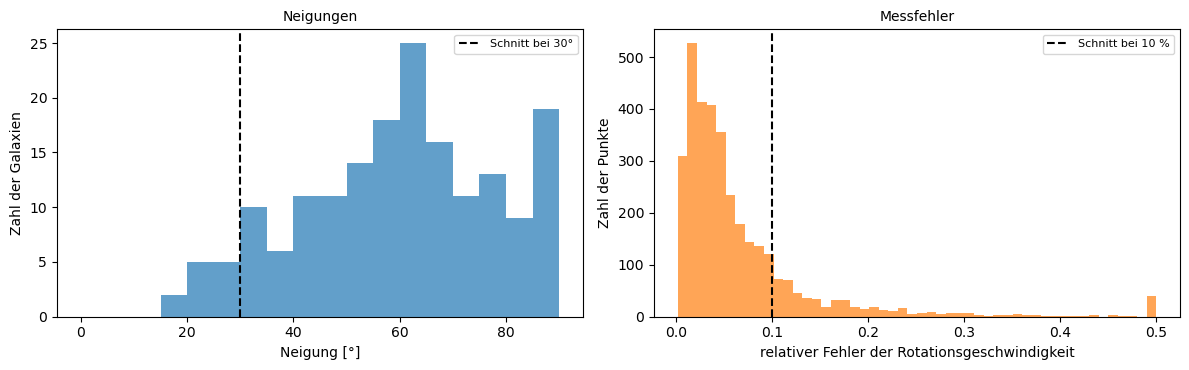

In [4]:
def v_bar_sq(d, ups_disk=UPS_DISK, ups_bul=UPS_BUL):
    # Theorie, Abschnitt 2: Gas mit Vorzeichen, Sterne mit Masse-Leuchtkraft-Verhältnis
    return np.abs(d["Vgas"]) * d["Vgas"] + ups_disk * d["Vdisk"] ** 2 + ups_bul * d["Vbul"] ** 2

pts = pd.concat([d.assign(Galaxy=name) for name, d in rotmod.items()], ignore_index=True)
pts = pts.merge(sparc[["Galaxy", "Q", "Inc"]], on="Galaxy")
pts["vb2"] = v_bar_sq(pts)
steps = [("alle", np.ones(len(pts), bool)),
         ("Qualität 1 oder 2", pts["Q"] < 3),
         ("Neigung >= 30°", pts["Inc"] >= 30),
         ("Fehler < 10 % von V_obs", pts["errV"] < 0.1 * pts["Vobs"]),
         ("V_obs > 0 und V_bar² > 0", (pts["Vobs"] > 0) & (pts["vb2"] > 0))]
keep = np.ones(len(pts), bool)
for label, m in steps:
    keep &= m
    print(f"{label:28s} {keep.sum():5d} Punkte aus {pts.loc[keep, 'Galaxy'].nunique():3d} Galaxien")
pts_ok = pts[keep]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(sparc["Inc"], bins=np.arange(0, 95, 5), color="tab:blue", alpha=0.7)
axes[0].axvline(30, color="black", ls="--", label="Schnitt bei 30°")
axes[0].set_xlabel("Neigung [°]")
axes[0].set_ylabel("Zahl der Galaxien")
axes[0].set_title("Neigungen", fontsize=10)
axes[0].legend(fontsize=8)
axes[1].hist(np.clip(pts["errV"] / pts["Vobs"], 0, 0.5), bins=50, color="tab:orange", alpha=0.7)
axes[1].axvline(0.1, color="black", ls="--", label="Schnitt bei 10 %")
axes[1].set_xlabel("relativer Fehler der Rotationsgeschwindigkeit")
axes[1].set_ylabel("Zahl der Punkte")
axes[1].set_title("Messfehler", fontsize=10)
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

* Die **Ausgabe** zeigt die Wirkung jedes Schnitts: Von 3391 Punkten aus 175 Galaxien bleiben nach der Qualität 3271, nach der Neigung 3168 und nach dem Fehler 2696 Punkte aus 147 Galaxien. Der Schnitt auf den Fehler entfernt am meisten, fast 500 Punkte.
* Das **linke Bild** zeigt die Neigungen der Galaxien: Die meisten liegen zwischen 40° und 90°, nur wenige unter dem Schnitt bei 30°. Das **rechte Bild** zeigt die relativen Fehler der Punkte: Die meisten liegen unter 5 %, ein langer Ausläufer reicht bis 50 % (am Rand gestapelt), und der Schnitt bei 10 % trennt ihn ab.

#### **Eigene Messung**

##### *3. Sichtbare Materie gegen beobachtete Rotation*

Wie schnell würde die Galaxie rotieren, wenn es nur Sterne und Gas gäbe, und ab welchem Radius reicht die sichtbare Masse nicht mehr aus? Vorher vorhersagen: Wie viel Prozent der Masse innerhalb des letzten Messpunkts fehlen?

Für NGC 2403 werden die Beiträge von Gas, Sternscheibe ($\Upsilon = 0.5$) und Bulge im Quadrat addiert und mit der beobachteten Kurve verglichen; daraus folgt der Anteil der Dunklen Materie innerhalb jedes Radius (Theorie, Abschnitt 2).

**Hintergrund & Fachbegriffe:**
- **$V_\text{bar}$:** die Rotation, die Sterne und Gas allein erzeugen würden.
- **Anteil der Dunklen Materie:** $1 - V_\text{bar}^2/V_\text{obs}^2$, der Teil der Masse innerhalb von $r$, den Sterne und Gas nicht erklären.
- **Dynamische Masse:** die Masse aus der Rotation, $V^2r/G$.

Bei 2.2 Skalenlängen (3.1 kpc): V_bar = 74 km/s, V_obs = 102 km/s, Anteil Dunkle Materie 47%
Am letzten Punkt (20.9 kpc): V_bar = 51 km/s, V_obs = 134 km/s, Anteil Dunkle Materie 85%
Ab 3.5 kpc (= 2.5 Skalenlängen) bleibt der Anteil der Dunklen Materie über 50 %
Masse innerhalb 21 kpc (kugelsymmetrisch genähert): gesamt 8.71e+10 M_sun, sichtbar 1.28e+10 M_sun


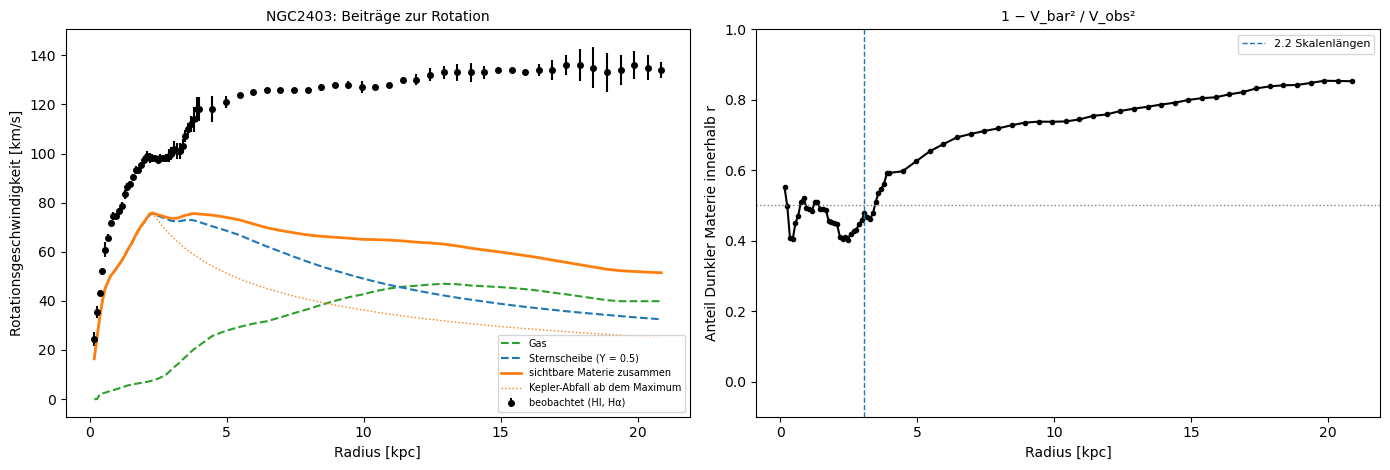

In [5]:
r_kpc = rc["R"].to_numpy()
v_obs = rc["Vobs"].to_numpy()
v_bar = np.sqrt(np.clip(v_bar_sq(rc), 0, None)).to_numpy()
f_dm = 1 - v_bar ** 2 / v_obs ** 2                                    # Theorie, Abschnitt 2
r22 = 2.2 * props["Rdisk"]                                            # dort hat eine exponentielle Scheibe ihr Maximum
print(f"Bei 2.2 Skalenlängen ({r22:.1f} kpc): V_bar = {np.interp(r22, r_kpc, v_bar):.0f} km/s, V_obs = {np.interp(r22, r_kpc, v_obs):.0f} km/s, "
      f"Anteil Dunkle Materie {np.interp(r22, r_kpc, f_dm):.0%}")
print(f"Am letzten Punkt ({r_kpc[-1]:.1f} kpc): V_bar = {v_bar[-1]:.0f} km/s, V_obs = {v_obs[-1]:.0f} km/s, Anteil Dunkle Materie {f_dm[-1]:.0%}")
below = np.flatnonzero(f_dm <= 0.5)
r_half = r_kpc[below[-1] + 1] if len(below) and below[-1] + 1 < len(r_kpc) else (r_kpc[0] if not len(below) else np.nan)
print(f"Ab {r_half:.1f} kpc (= {r_half / props['Rdisk']:.1f} Skalenlängen) bleibt der Anteil der Dunklen Materie über 50 %")
m_dyn = v_obs[-1] ** 2 * r_kpc[-1] / G_KPC
m_bar = v_bar[-1] ** 2 * r_kpc[-1] / G_KPC
print(f"Masse innerhalb {r_kpc[-1]:.0f} kpc (kugelsymmetrisch genähert): gesamt {m_dyn:.2e} M_sun, sichtbar {m_bar:.2e} M_sun")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
ax = axes[0]
ax.errorbar(r_kpc, v_obs, rc["errV"], fmt="o", c="black", ms=4, label="beobachtet (HI, Hα)")
ax.plot(r_kpc, rc["Vgas"], c="tab:green", ls="--", label="Gas")
ax.plot(r_kpc, np.sqrt(UPS_DISK) * rc["Vdisk"], c="tab:blue", ls="--", label=f"Sternscheibe (Υ = {UPS_DISK})")
if rc["Vbul"].max() > 0:
    ax.plot(r_kpc, np.sqrt(UPS_BUL) * rc["Vbul"], c="tab:purple", ls="--", label=f"Bulge (Υ = {UPS_BUL})")
ax.plot(r_kpc, v_bar, c="tab:orange", lw=2, label="sichtbare Materie zusammen")
r_kep = np.linspace(r_kpc[np.argmax(v_bar)], r_kpc[-1], 50)
ax.plot(r_kep, v_bar.max() * np.sqrt(r_kpc[np.argmax(v_bar)] / r_kep), c="tab:orange", ls=":", lw=1, label="Kepler-Abfall ab dem Maximum")
ax.set_xlabel("Radius [kpc]")
ax.set_ylabel("Rotationsgeschwindigkeit [km/s]")
ax.set_title(f"{SPARC_GALAXY}: Beiträge zur Rotation", fontsize=10)
ax.legend(fontsize=7, loc="lower right")
axes[1].plot(r_kpc, f_dm, "o-", c="black", ms=3)
axes[1].axhline(0.5, color="grey", ls=":", lw=1)
axes[1].axvline(r22, color="tab:blue", ls="--", lw=1, label="2.2 Skalenlängen")
axes[1].set_ylim(-0.1, 1)
axes[1].set_xlabel("Radius [kpc]")
axes[1].set_ylabel("Anteil Dunkler Materie innerhalb r")
axes[1].set_title("1 − V_bar² / V_obs²", fontsize=10)
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

* Das **linke Bild** zeigt die Beiträge zur Rotation von NGC 2403: Die Sternscheibe (blau gestrichelt) dominiert innen und fällt nach ihrem Maximum bei etwa 3 kpc ab, das Gas (grün) steigt langsam an und überwiegt ab etwa 11 kpc. Zusammen (orange) erreichen sie höchstens 76 km/s und fallen dann ab, langsamer als der Kepler-Abfall (gepunktet), weil das Gas außen noch Masse hinzufügt. Die beobachtete Kurve (schwarz) steigt dagegen weiter auf 134 km/s.
* Das **rechte Bild** zeigt den Anteil der Dunklen Materie: Schon innen liegt er um 40 bis 55 %, ab 3.5 kpc bleibt er über 50 % und steigt bis zum letzten Punkt auf 85 %.
* Die **Ausgabe** gibt die Zahlen: Bei 2.2 Skalenlängen (3.1 kpc) liefert die sichtbare Materie 74 von 102 km/s, also 73 %; eine maximale Scheibe hätte dort etwa 85 %, die Scheibe ist mit $\Upsilon = 0.5$ also nicht maximal. Innerhalb von 21 kpc hat die Galaxie $8.7\cdot10^{10}\,M_\odot$, sichtbar sind nur $1.3\cdot10^{10}\,M_\odot$.

#### **Modell und Fit**

##### *4. NFW-Halo gegen Halo mit Kern*

Beschreibt ein Halo, wie ihn Simulationen vorhersagen, die fehlende Rotation besser als ein Halo mit flachem Kern? Vorher vorhersagen: Welcher Halo steigt innen schneller an?

Zur sichtbaren Materie wird ein NFW-Halo (Parameter $V_{200}$ und $c$) oder ein pseudo-isothermer Halo ($V_\infty$ und $r_c$) addiert und an die beobachtete Kurve angepasst, gewichtet mit den Fehlern (mindestens 1 km/s). Verglichen werden das reduzierte χ² und die Residuen in Einheiten der Fehler (Theorie, Abschnitte 3 und 6).

**Hintergrund & Fachbegriffe:**
- **NFW-Profil:** die Dichte von Halos in Simulationen mit kalter Dunkler Materie, innen steil ansteigend (Cusp).
- **Pseudo-isothermes Profil:** ein Halo mit flacher Dichte im Zentrum (Kern).
- **$M_{200}$, $R_{200}$:** Masse und Radius des Halos bis zur 200-fachen kritischen Dichte; ein übliches Maß für die Größe eines Halos.
- **Residuum:** gemessener minus Modellwert, hier geteilt durch den Fehler.

NFW:       V200 = 104 ± 1 km/s, c = 10.1 ± 0.2, R200 = 142 kpc, M200 = 3.6e+11 M_sun, r_s = 14.1 kpc;  χ²_red = 4.89
Mit Kern:  V_inf = 127 ± 1 km/s, r_c = 1.65 ± 0.03 kpc;  χ²_red = 12.75
Besser passt NFW (χ²_red 4.89 gegen 12.75)
Sichtbare Masse gegen Halo: M_bar(gesamt) = 9.3e+09 M_sun, M200 / M_bar = 38


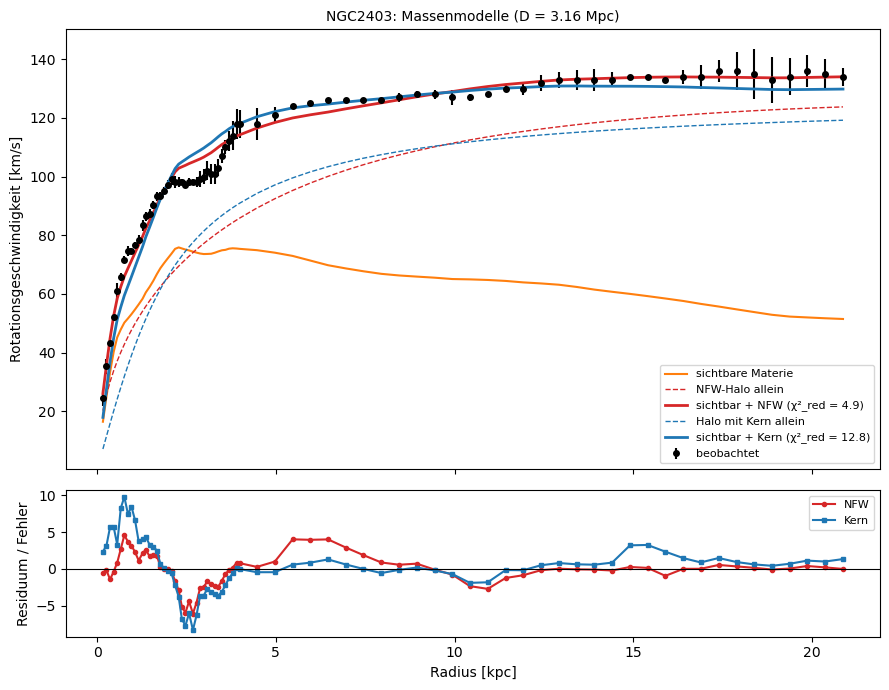

In [6]:
def v_nfw(r, v200, c):
    # Theorie, Abschnitt 3 (NFW)
    x = r / (v200 / (10 * H0_KPC))
    return v200 * np.sqrt((np.log(1 + c * x) - c * x / (1 + c * x)) / (x * (np.log(1 + c) - c / (1 + c))))

def v_iso(r, v_inf, r_c):
    # Theorie, Abschnitt 3 (pseudo-isotherm)
    return v_inf * np.sqrt(1 - r_c / r * np.arctan(r / r_c))

err = np.maximum(rc["errV"].to_numpy(), 1.0)
p_nfw, c_nfw = curve_fit(lambda r, v200, c: np.sqrt(v_bar ** 2 + v_nfw(r, v200, c) ** 2), r_kpc, v_obs,
                         p0=[150, 10], sigma=err, absolute_sigma=True, bounds=([10, 1], [500, 40]))
p_iso, c_iso = curve_fit(lambda r, vi, rcore: np.sqrt(v_bar ** 2 + v_iso(r, vi, rcore) ** 2), r_kpc, v_obs,
                         p0=[150, 2], sigma=err, absolute_sigma=True, bounds=([5, 0.05], [500, 50]))
v_tot_nfw = np.sqrt(v_bar ** 2 + v_nfw(r_kpc, *p_nfw) ** 2)
v_tot_iso = np.sqrt(v_bar ** 2 + v_iso(r_kpc, *p_iso) ** 2)
dof = len(r_kpc) - 2
chi2_nfw = np.sum(((v_obs - v_tot_nfw) / err) ** 2) / dof
chi2_iso = np.sum(((v_obs - v_tot_iso) / err) ** 2) / dof
r200 = p_nfw[0] / (10 * H0_KPC)
m200 = p_nfw[0] ** 2 * r200 / G_KPC
print(f"NFW:       V200 = {p_nfw[0]:.0f} ± {np.sqrt(c_nfw[0, 0]):.0f} km/s, c = {p_nfw[1]:.1f} ± {np.sqrt(c_nfw[1, 1]):.1f}, "
      f"R200 = {r200:.0f} kpc, M200 = {m200:.1e} M_sun, r_s = {r200 / p_nfw[1]:.1f} kpc;  χ²_red = {chi2_nfw:.2f}")
print(f"Mit Kern:  V_inf = {p_iso[0]:.0f} ± {np.sqrt(c_iso[0, 0]):.0f} km/s, r_c = {p_iso[1]:.2f} ± {np.sqrt(c_iso[1, 1]):.2f} kpc;  "
      f"χ²_red = {chi2_iso:.2f}")
print(f"Besser passt {'NFW' if chi2_nfw < chi2_iso else 'der Halo mit Kern'} (χ²_red {min(chi2_nfw, chi2_iso):.2f} gegen {max(chi2_nfw, chi2_iso):.2f})")
print(f"Sichtbare Masse gegen Halo: M_bar(gesamt) = {(UPS_DISK * props['L36'] + 1.33 * props['MHI']) * 1e9:.1e} M_sun, "
      f"M200 / M_bar = {m200 / ((UPS_DISK * props['L36'] + 1.33 * props['MHI']) * 1e9):.0f}")

fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
axes[0].errorbar(r_kpc, v_obs, rc["errV"], fmt="o", c="black", ms=4, label="beobachtet")
axes[0].plot(r_kpc, v_bar, c="tab:orange", lw=1.5, label="sichtbare Materie")
axes[0].plot(r_kpc, v_nfw(r_kpc, *p_nfw), c="tab:red", ls="--", lw=1, label="NFW-Halo allein")
axes[0].plot(r_kpc, v_tot_nfw, c="tab:red", lw=2, label=f"sichtbar + NFW (χ²_red = {chi2_nfw:.1f})")
axes[0].plot(r_kpc, v_iso(r_kpc, *p_iso), c="tab:blue", ls="--", lw=1, label="Halo mit Kern allein")
axes[0].plot(r_kpc, v_tot_iso, c="tab:blue", lw=2, label=f"sichtbar + Kern (χ²_red = {chi2_iso:.1f})")
axes[0].set_ylabel("Rotationsgeschwindigkeit [km/s]")
axes[0].set_title(f"{SPARC_GALAXY}: Massenmodelle (D = {props['D']:.2f} Mpc)", fontsize=10)
axes[0].legend(fontsize=8, loc="lower right")
axes[1].plot(r_kpc, (v_obs - v_tot_nfw) / err, "o-", c="tab:red", ms=3, label="NFW")
axes[1].plot(r_kpc, (v_obs - v_tot_iso) / err, "s-", c="tab:blue", ms=3, label="Kern")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_xlabel("Radius [kpc]")
axes[1].set_ylabel("Residuum / Fehler")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

* Das **obere Bild** zeigt die beobachtete Kurve mit beiden Massenmodellen: sichtbare Materie (orange), die Halos allein (gestrichelt) und die Summen (durchgezogen). Beide Summen folgen der Kurve im Großen; der Halo mit Kern (blau) steigt innen aber zu langsam an. Das **untere Bild** zeigt die Residuen: Unter 1.5 kpc liegt die Messung beim Halo mit Kern bis zu zehn Fehlerbalken über dem Modell, beim NFW-Halo nur bis drei.
* Die **Ausgabe** gibt die Parameter: NFW mit $V_{200} = 104$ km/s, $c = 10.1$, $R_{200} = 142$ kpc und $M_{200} = 3.6\cdot10^{11}\,M_\odot$, χ²_red 4.9; der Halo mit Kern $V_\infty = 127$ km/s, $r_c = 1.65$ kpc, χ²_red 12.8. Für NGC 2403 passt also das NFW-Profil besser.
* Beide Modelle verfehlen eine Stufe der Kurve bei 2 bis 3 kpc, deshalb ist χ²_red deutlich größer als 1; dort könnten nicht-kreisförmige Bewegungen oder zu kleine Fehlerbalken stecken. Der Halo hat 38-mal die sichtbare Masse; nach dem kosmischen Verhältnis von Baryonen zu Materie (etwa 0.16) wären es 6, NGC 2403 enthält also nur etwa ein Sechstel der Baryonen, die zu seinem Halo gehören.

##### *5. Die radiale Beschleunigungsrelation*

Hängt die gemessene Beschleunigung in allen Galaxien auf dieselbe Weise von der Beschleunigung durch die sichtbare Materie ab, und bei welcher Beschleunigung beginnt die Abweichung? Vorher vorhersagen: Wie stark streuen die Punkte von 147 verschiedenen Galaxien um eine einzige Kurve?

Für alle 2696 Punkte werden $g_\text{obs}$ und $g_\text{bar}$ berechnet und die Formel von McGaugh, Lelli & Schombert mit dem einzigen Parameter $g_\dagger$ in logarithmischen Größen angepasst (Theorie, Abschnitt 4).

**Hintergrund & Fachbegriffe:**
- **$g_\text{obs}$ und $g_\text{bar}$:** die Beschleunigung aus der gemessenen Rotation und die aus Sternen und Gas allein.
- **dex:** eine Zehnerpotenz; eine Streuung von 0.13 dex ist ein Faktor 1.35.
- **Hexbin-Diagramm:** zählt die Punkte in sechseckigen Feldern; dunkle Felder enthalten viele Punkte.

2,696 Punkte aus 147 Galaxien
g† = (1.161 ± 0.018)·10⁻¹⁰ m/s² (nur statistischer Fehler)
Streuung um die Kurve: 0.133 dex; ohne Dunkle Materie (g_obs = g_bar): 0.281 dex um einen Mittelwert von +0.43 dex
  log g_bar in [-12.5, -11.5):  155 Punkte, g_obs/g_bar im Median   7.8
  log g_bar in [-11.5, -10.5): 1296 Punkte, g_obs/g_bar im Median   3.9
  log g_bar in [-10.5, -9.5):  933 Punkte, g_obs/g_bar im Median   1.8
  log g_bar in [-9.5, -8.5):  302 Punkte, g_obs/g_bar im Median   1.1


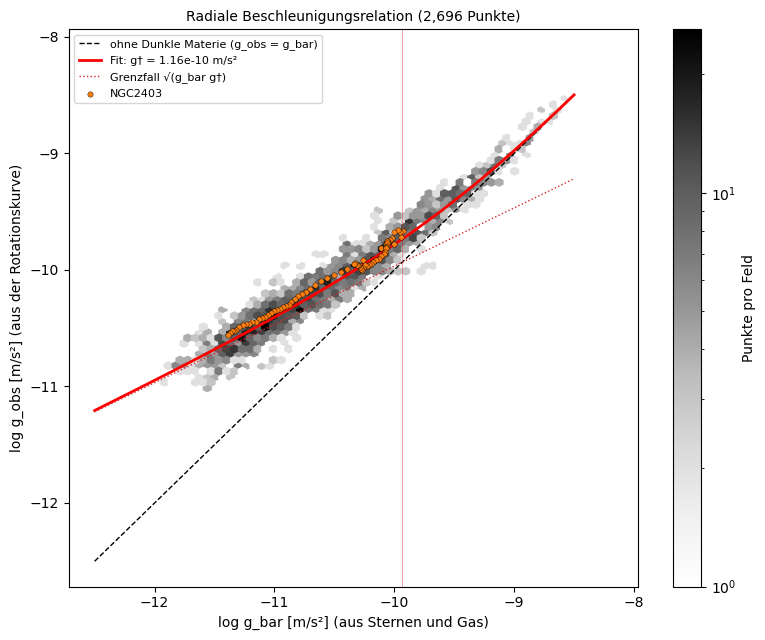

In [7]:
g_obs = pts_ok["Vobs"] ** 2 / pts_ok["R"] * ACC
g_bar = pts_ok["vb2"] / pts_ok["R"] * ACC
def rar(gb, gdag):
    return gb / (1 - np.exp(-np.sqrt(gb / gdag)))          # Theorie, Abschnitt 4
lg_dag, lg_cov = curve_fit(lambda lg, lgd: np.log10(rar(10 ** lg, 10 ** lgd)), np.log10(g_bar), np.log10(g_obs), p0=[-10.0])
gdag = 10 ** lg_dag[0]
gdag_err = gdag * np.log(10) * np.sqrt(lg_cov[0, 0])
resid = np.log10(g_obs) - np.log10(rar(g_bar, gdag))
print(f"{len(pts_ok):,} Punkte aus {pts_ok['Galaxy'].nunique()} Galaxien")
print(f"g† = ({gdag * 1e10:.3f} ± {gdag_err * 1e10:.3f})·10⁻¹⁰ m/s² (nur statistischer Fehler)")
print(f"Streuung um die Kurve: {resid.std():.3f} dex; ohne Dunkle Materie (g_obs = g_bar): {np.std(np.log10(g_obs / g_bar)):.3f} dex "
      f"um einen Mittelwert von {np.mean(np.log10(g_obs / g_bar)):+.2f} dex")
for lo, hi in [(-12.5, -11.5), (-11.5, -10.5), (-10.5, -9.5), (-9.5, -8.5)]:
    m = (np.log10(g_bar) >= lo) & (np.log10(g_bar) < hi)
    if m.sum():
        print(f"  log g_bar in [{lo}, {hi}): {m.sum():4d} Punkte, g_obs/g_bar im Median {np.median(g_obs[m] / g_bar[m]):5.1f}")

fig, ax = plt.subplots(figsize=(8, 6.5))
hb = ax.hexbin(np.log10(g_bar), np.log10(g_obs), gridsize=60, bins="log", cmap="Greys", mincnt=1)
gb = np.logspace(-12.5, -8.5, 200)
ax.plot(np.log10(gb), np.log10(gb), "k--", lw=1, label="ohne Dunkle Materie (g_obs = g_bar)")
ax.plot(np.log10(gb), np.log10(rar(gb, gdag)), "r-", lw=2, label=f"Fit: g† = {gdag:.2e} m/s²")
ax.plot(np.log10(gb), 0.5 * np.log10(gb * gdag), c="tab:red", ls=":", lw=1, label="Grenzfall √(g_bar g†)")
own = (v_bar > 0) & (v_obs > 0)
ax.scatter(np.log10((v_bar ** 2 / r_kpc * ACC)[own]), np.log10((v_obs ** 2 / r_kpc * ACC)[own]), c="tab:orange", s=15,
           edgecolor="k", lw=0.3, zorder=3, label=SPARC_GALAXY)
ax.axvline(np.log10(gdag), color="tab:red", lw=0.6, alpha=0.5)
fig.colorbar(hb, ax=ax, label="Punkte pro Feld")
ax.set_xlabel("log g_bar [m/s²] (aus Sternen und Gas)")
ax.set_ylabel("log g_obs [m/s²] (aus der Rotationskurve)")
ax.set_title(f"Radiale Beschleunigungsrelation ({len(pts_ok):,} Punkte)", fontsize=10)
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

* Das **Bild** zeigt $g_\text{obs}$ gegen $g_\text{bar}$ für alle Punkte (grau), logarithmisch. Ohne Dunkle Materie lägen sie auf der gestrichelten Diagonale; tatsächlich liegen sie bei hohen Beschleunigungen nahe daran und biegen unter etwa $10^{-10}$ m/s² nach oben ab, auf die gepunktete Grenzlinie $\sqrt{g_\text{bar}g_\dagger}$ zu. Die rote Kurve mit $g_\dagger = 1.16\cdot10^{-10}$ m/s² folgt der Wolke über vier Größenordnungen, und auch die Punkte von NGC 2403 (orange) liegen darauf.
* Die **Ausgabe** gibt die Zahlen: $g_\dagger = (1.161\pm0.018)\cdot10^{-10}$ m/s² und eine Streuung von nur 0.13 dex um die Kurve; ohne Dunkle Materie wären es 0.28 dex um einen Versatz von +0.43 dex. Bei $g_\text{bar}\approx10^{-9}$ m/s² ist $g_\text{obs}/g_\text{bar} = 1.1$, bei $10^{-12}$ m/s² 7.8.
* Dass 147 sehr verschiedene Galaxien, von Zwergen bis zu großen Spiralen, so eng auf einer Kurve liegen, ist der überraschende Teil: Aus der Verteilung der sichtbaren Materie folgt die Rotation fast vollständig, obwohl die Dunkle Materie den größten Teil der Masse stellt.

##### *6. Die baryonische Tully-Fisher-Beziehung*

Wie hängt die gesamte sichtbare Masse einer Galaxie von ihrer flachen Rotationsgeschwindigkeit ab, und passt die Beziehung zu $M_\text{bar} = V^4/(G g_\dagger)$ aus Schritt 5? Vorher vorhersagen: Wird die gewöhnliche Regression steiler oder flacher als die orthogonale?

Für 129 Galaxien der Qualität 1 oder 2 mit $V_\text{flat}$ wird die sichtbare Masse aus Leuchtkraft und HI-Masse berechnet und $\log M_\text{bar}$ gegen $\log V_\text{flat}$ angepasst, einmal mit orthogonaler Regression (Fehler 0.1 dex in der Masse und der Fehler von $V_\text{flat}$) und einmal gewöhnlich (Theorie, Abschnitte 5 und 6).

**Hintergrund & Fachbegriffe:**
- **Tully-Fisher-Beziehung:** ursprünglich zwischen Leuchtkraft und Rotationsgeschwindigkeit (1977), zur Entfernungsmessung; die baryonische Form nimmt Sterne und Gas zusammen.
- **Gasanteil:** der Anteil des Gases an der sichtbaren Masse; in Zwerggalaxien oft der größte Teil.
- **Orthogonale Regression:** minimiert die Abstände senkrecht zur Geraden mit Fehlern in beiden Achsen.

129 Galaxien mit V_flat und Qualität 1 oder 2
Orthogonale Regression: log M_bar = (3.56 ± 0.09) log V_flat + (2.60 ± 0.19), Streuung 0.25 dex
Gewöhnliche Regression: Steigung 3.41 (zu flach, Theorie Abschnitt 6)
Aus g†: Steigung 4, log M_bar = 4 log V_flat + 1.81;  bei V_flat = 100 km/s: Fit 5.33e+09, Vorhersage 6.49e+09 M_sun
Gasanteil: von 2% bis 95%; Median unter 50 km/s 78%, über 200 km/s 13%


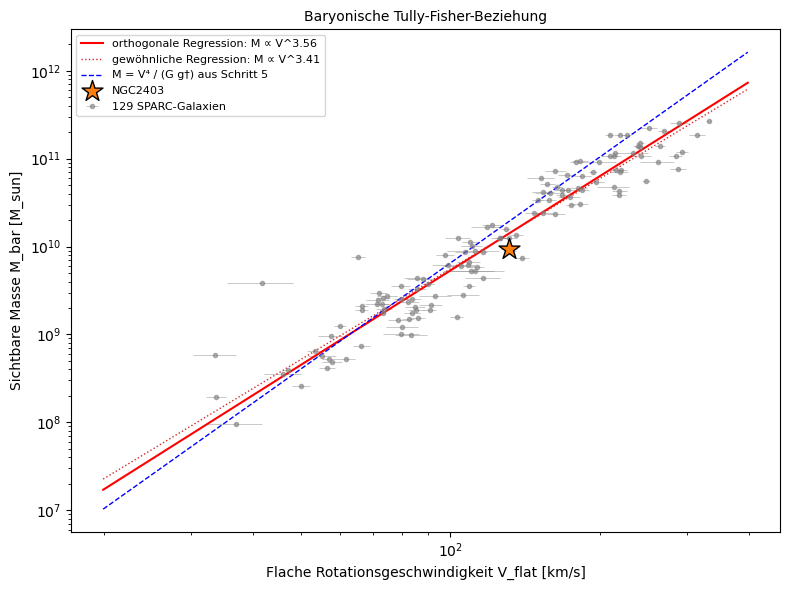

In [8]:
btf = sparc[(sparc["Vflat"] > 0) & (sparc["Q"] < 3)].copy()
btf["Mbar"] = (UPS_DISK * btf["L36"] + 1.33 * btf["MHI"]) * 1e9           # Theorie, Abschnitt 5
x_btf, y_btf = np.log10(btf["Vflat"]), np.log10(btf["Mbar"])
sx = btf["e_Vflat"] / btf["Vflat"] / np.log(10)                            # Fehler von log V
sy = np.full(len(btf), 0.1)                                                # 0.1 dex für Masse-Leuchtkraft und Entfernung
fit = odr.ODR(odr.RealData(x_btf, y_btf, sx=sx, sy=sy), odr.unilinear, beta0=[4.0, 2.0]).run()
slope, icpt = fit.beta
slope_err, icpt_err = fit.sd_beta
slope_ols, icpt_ols = np.polyfit(x_btf, y_btf, 1)
scatter = np.std(y_btf - (icpt + slope * x_btf))

# Vorhersage aus der Beschleunigungsrelation: M = V^4 / (G g†)
G_SI, MSUN = 6.674e-11, 1.989e30
def m_pred(v_kms):
    return (v_kms * 1e3) ** 4 / (G_SI * gdag) / MSUN
icpt_pred = np.log10(m_pred(1.0))
print(f"{len(btf)} Galaxien mit V_flat und Qualität 1 oder 2")
print(f"Orthogonale Regression: log M_bar = ({slope:.2f} ± {slope_err:.2f}) log V_flat + ({icpt:.2f} ± {icpt_err:.2f}), "
      f"Streuung {scatter:.2f} dex")
print(f"Gewöhnliche Regression: Steigung {slope_ols:.2f} (zu flach, Theorie Abschnitt 6)")
print(f"Aus g†: Steigung 4, log M_bar = 4 log V_flat + {icpt_pred:.2f};  bei V_flat = 100 km/s: "
      f"Fit {10 ** (icpt + 2 * slope):.2e}, Vorhersage {m_pred(100):.2e} M_sun")
print(f"Gasanteil: von {(1.33 * btf['MHI'] * 1e9 / btf['Mbar']).min():.0%} bis {(1.33 * btf['MHI'] * 1e9 / btf['Mbar']).max():.0%}; "
      f"Median unter 50 km/s {(1.33 * btf['MHI'] * 1e9 / btf['Mbar'])[btf['Vflat'] < 50].median():.0%}, "
      f"über 200 km/s {(1.33 * btf['MHI'] * 1e9 / btf['Mbar'])[btf['Vflat'] > 200].median():.0%}")

fig, ax = plt.subplots(figsize=(8, 6))
ax.errorbar(btf["Vflat"], btf["Mbar"], xerr=btf["e_Vflat"], fmt="o", ms=3, c="grey", alpha=0.6, lw=0.5,
            label=f"{len(btf)} SPARC-Galaxien")
vv = np.logspace(1.3, 2.6, 50)
ax.plot(vv, 10 ** icpt * vv ** slope, "r-", label=f"orthogonale Regression: M ∝ V^{slope:.2f}")
ax.plot(vv, 10 ** icpt_ols * vv ** slope_ols, c="tab:red", ls=":", lw=1, label=f"gewöhnliche Regression: M ∝ V^{slope_ols:.2f}")
ax.plot(vv, m_pred(vv), "b--", lw=1, label="M = V⁴ / (G g†) aus Schritt 5")
if props["Vflat"] > 0:
    ax.scatter([props["Vflat"]], [(UPS_DISK * props["L36"] + 1.33 * props["MHI"]) * 1e9], marker="*", s=250,
               c="tab:orange", edgecolor="k", zorder=5, label=SPARC_GALAXY)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Flache Rotationsgeschwindigkeit V_flat [km/s]")
ax.set_ylabel("Sichtbare Masse M_bar [M_sun]")
ax.set_title("Baryonische Tully-Fisher-Beziehung", fontsize=10)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

* Das **Bild** zeigt die sichtbare Masse gegen $V_\text{flat}$ für 129 Galaxien, doppelt logarithmisch, mit den beiden Regressionen (rot) und der Vorhersage $V^4/(Gg_\dagger)$ (blau gestrichelt); NGC 2403 ist der Stern. Die Punkte liegen auf einem engen Band über mehr als drei Größenordnungen in der Masse. Bei kleinen Geschwindigkeiten liegen sie auf oder über der blauen Linie, bei den schnellsten Galaxien darunter.
* Die **Ausgabe** gibt die Steigung $3.56\pm0.09$ mit orthogonaler Regression, Streuung 0.25 dex; die gewöhnliche Regression gibt die flachere Steigung 3.41, wie bei Fehlern in $x$ zu erwarten. Die Vorhersage aus $g_\dagger$ trifft die Masse bei 100 km/s auf 0.09 dex ($6.5\cdot10^9$ gegen $5.3\cdot10^9\,M_\odot$).
* Die massereichen Galaxien liegen unter der Vorhersage, weil bei ihnen $g_\text{bar}$ auch außen nicht klein gegen $g_\dagger$ ist und die Näherung $\sqrt{g_\text{bar}g_\dagger}$ nicht gilt. Bei Zwerggalaxien unter 50 km/s ist das Gas im Median 78 % der sichtbaren Masse, über 200 km/s nur 13 %; ohne das Gas wäre die Beziehung nicht so eng.

#### **Eigene Messung gegen den Katalog**

##### *7. Vergleich mit den SPARC-Veröffentlichungen*

Stimmen $g_\dagger$, die Streuung der Beschleunigungsrelation und die Steigung der Tully-Fisher-Beziehung mit den Werten des SPARC-Teams überein? Vorher vorhersagen: Wie viel weicht $g_\dagger$ ab, wenn man dieselben Schnitte verwendet?

Die eigenen Werte stehen in einer Tabelle neben den veröffentlichten von McGaugh, Lelli & Schombert (2016) und Lelli et al. (2016, 2019), dazu die flache Geschwindigkeit von NGC 2403 aus den letzten drei Punkten neben dem Tabellenwert.

**Hintergrund & Fachbegriffe:**
- **Statistischer und systematischer Fehler:** Der statistische kommt aus der Streuung der Daten, der systematische aus Annahmen wie dem Masse-Leuchtkraft-Verhältnis; bei $g_\dagger$ ist der systematische zehnmal größer.

In [9]:
rows = [("g† [10⁻¹⁰ m/s²]", f"{gdag * 1e10:.2f} ± {gdag_err * 1e10:.2f}", "1.20 ± 0.02 (stat.) ± 0.24 (syst.)", "McGaugh, Lelli & Schombert (2016)"),
        ("Streuung der Beschleunigungsrelation [dex]", f"{resid.std():.2f}", "0.13", "McGaugh, Lelli & Schombert (2016)"),
        ("Zahl der Punkte", f"{len(pts_ok):,}", "2,693", "McGaugh, Lelli & Schombert (2016)"),
        ("Steigung der Tully-Fisher-Beziehung", f"{slope:.2f} ± {slope_err:.2f}", "etwa 3.5 bis 4, je nach Methode", "Lelli et al. (2016, 2019)"),
        (f"V_flat von {SPARC_GALAXY} [km/s]", f"{np.mean(v_obs[-3:]):.0f} (Mittel der letzten 3 Punkte)",
         f"{props['Vflat']:.0f} ± {props['e_Vflat']:.0f}", "SPARC-Tabelle")]
print(pd.DataFrame(rows, columns=["Größe", "eigen", "veröffentlicht", "Quelle"]).to_string(index=False))

                                     Größe                             eigen                     veröffentlicht                            Quelle
                           g† [10⁻¹⁰ m/s²]                       1.16 ± 0.02 1.20 ± 0.02 (stat.) ± 0.24 (syst.) McGaugh, Lelli & Schombert (2016)
Streuung der Beschleunigungsrelation [dex]                              0.13                               0.13 McGaugh, Lelli & Schombert (2016)
                           Zahl der Punkte                             2,696                              2,693 McGaugh, Lelli & Schombert (2016)
       Steigung der Tully-Fisher-Beziehung                       3.56 ± 0.09    etwa 3.5 bis 4, je nach Methode         Lelli et al. (2016, 2019)
                 V_flat von NGC2403 [km/s] 135 (Mittel der letzten 3 Punkte)                            131 ± 5                     SPARC-Tabelle


* Die **Tabelle** zeigt: $g_\dagger = 1.16\cdot10^{-10}$ m/s² liegt 3 % unter dem veröffentlichten Wert $1.20\cdot10^{-10}$, weit innerhalb des systematischen Fehlers von 20 %. Streuung (0.13 dex) und Zahl der Punkte (2696 gegen 2693) stimmen, weil dieselben Schnitte verwendet sind.
* Die Steigung der Tully-Fisher-Beziehung, 3.56, liegt im veröffentlichten Bereich von etwa 3.5 bis 4, der von der Definition der Geschwindigkeit und der Fit-Methode abhängt. Die flache Geschwindigkeit von NGC 2403 aus den letzten drei Punkten (135 km/s) stimmt mit dem Tabellenwert (131 ± 5 km/s) überein.

#### **Ergebnis**

Beim Lauf vom 2026-10-12 (NGC 2403):

- **Daten:** SPARC enthält 175 Galaxien mit 3 391 Punkten, von S0 bis zu irregulären Zwerggalaxien (am häufigsten Im und Sm), mit $V_\text{flat}$ von 19 bis 332 km/s. NGC 2403 (Typ Scd, 3.16 Mpc, Neigung 63°) hat 73 Punkte bis 20.9 kpc, das sind 15 Skalenlängen der Scheibe: Das HI reicht weit über die Sterne hinaus.
- **Qualitätsschnitte:** Qualität 1–2, Neigung ab 30° und Fehler unter 10 % lassen 2 696 Punkte aus 147 Galaxien übrig.
- **Sichtbare Materie:** Sterne und Gas erreichen höchstens 76 km/s (bei 2.3 kpc) und fallen dann ab, die beobachtete Kurve steigt weiter auf 134 km/s. Bei 2.2 Skalenlängen liefert die sichtbare Materie 74 von 102 km/s, also 73 %; eine „maximale Scheibe“ hätte dort etwa 85 % (Sackett 1997). Mit $\Upsilon = 0.5$ ist die Scheibe also nicht maximal, und schon dort fehlt fast die Hälfte der Masse. Ab 3.5 kpc überwiegt die Dunkle Materie, am letzten Punkt macht sie 85 % aus: 8.7·10¹⁰ $M_\odot$ insgesamt gegen 1.3·10¹⁰ $M_\odot$ sichtbar innerhalb von 21 kpc. Weiter außen dominiert das Gas über die Sterne.
- **Halo-Modelle:** NFW passt besser (χ²_red 4.9 gegen 12.8). Der Halo mit Kern steigt innen zu langsam an und unterschätzt die Rotation unter 1.5 kpc um bis zu zehn Fehlerbalken. Die NFW-Parameter: $V_{200} = 104$ km/s, $c = 10.1$, $R_{200} = 142$ kpc, $M_{200} = 3.6 \cdot 10^{11}\,M_\odot$, 38-mal die sichtbare Masse. Nach dem kosmischen Verhältnis von Baryonen zu Materie (etwa 0.16) wären es 6; NGC 2403 enthält also nur etwa ein Sechstel der Baryonen, die zu seinem Halo gehören. Beide Modelle verfehlen eine Stufe der Kurve bei 2–3 kpc, deshalb ist χ²_red deutlich größer als 1; dort könnten nicht-kreisförmige Bewegungen oder zu kleine Fehlerbalken stecken.
- **Beschleunigungsrelation:** Die Punkte aller 147 Galaxien liegen auf einer Kurve mit $g_\dagger = (1.161 \pm 0.018) \cdot 10^{-10}$ m/s² und einer Streuung von 0.13 dex; ohne Dunkle Materie wäre die Streuung 0.28 dex um einen Versatz von +0.43 dex. Bei $g_\text{bar} \approx 10^{-9}$ m/s² ist $g_\text{obs}/g_\text{bar} = 1.1$, bei $10^{-12}$ m/s² 7.8. Auch die Punkte von NGC 2403 liegen auf der Kurve.
- **Tully-Fisher:** Mit orthogonaler Regression ist $M_\text{bar} \propto V_\text{flat}^{3.56 \pm 0.09}$ (129 Galaxien, Streuung 0.25 dex); die gewöhnliche Regression gibt 3.41. Die Vorhersage $M = V^4/(G g_\dagger)$ aus der Beschleunigungsrelation trifft die Masse bei 100 km/s auf 0.09 dex (6.5·10⁹ gegen 5.3·10⁹ $M_\odot$). Die massereichen Galaxien liegen darunter, weil bei ihnen $g_\text{bar}$ auch außen nicht klein gegen $g_\dagger$ ist und die Näherung $\sqrt{g_\text{bar} g_\dagger}$ aus Abschnitt 4 der Theorie nicht gilt. Bei Zwerggalaxien unter 50 km/s ist das Gas im Median 78 % der sichtbaren Masse, über 200 km/s nur 13 %.
- **Vergleich:** $g_\dagger$ liegt 3 % unter dem Wert von McGaugh, Lelli & Schombert (2016), weit innerhalb ihres systematischen Fehlers von 20 %; Streuung (0.13 dex) und Zahl der Punkte (2 696 gegen 2 693) stimmen, weil dieselben Schnitte verwendet sind. Die Steigung 3.56 liegt im veröffentlichten Bereich von etwa 3.5 bis 4. Die flache Geschwindigkeit von NGC 2403 aus den letzten drei Punkten (135 km/s) stimmt mit der SPARC-Tabelle (131 ± 5 km/s) überein.

#### **Variationen**

Jeweils zuerst die Vorhersage notieren, dann den Code ändern und prüfen:

1. **Eine große Spirale:** `GALAXY = "M 63"` (NGC 5055). Welcher Halo passt besser, und wie groß ist der Anteil der Dunklen Materie am letzten Punkt? *(Vorhersage: Bei 2.2 Skalenlängen erklären Sterne und Gas fast die ganze Rotation, die Scheibe ist nahezu maximal; am letzten Punkt bei 55 kpc fehlen etwa drei Viertel der Masse, und hier passt der Halo mit Kern besser als NFW. Welches Profil gewinnt, hängt also von der Galaxie ab.)*
2. **Eine Zwerggalaxie:** `GALAXY = "DDO 154"`. *(Vorhersage: Gas überwiegt die Sterne, die Dunkle Materie dominiert schon innen, und der Halo mit Kern passt besser als NFW: das Core-Cusp-Problem.)*
3. **Maximale Scheibe:** Setze `UPS_DISK` so hoch, dass die Scheibe allein die innere Rotationskurve erklärt (etwa 0.8 bis 1.0). Wie ändern sich die Halo-Parameter? *(Vorhersage: Der Halo wird kleiner und flacher; die Rotationskurve allein kann Scheibe und Halo nicht trennen.)*
4. **Andere Masse-Leuchtkraft-Verhältnisse in der Beschleunigungsrelation:** `UPS_DISK = 0.3` oder `0.7`. In welche Richtung verschiebt sich $g_\dagger$?
5. **Nur Sterne:** Lass in der Tully-Fisher-Beziehung das Gas weg. *(Vorhersage: Die gasreichen Zwerggalaxien fallen nach unten, die Steigung wird steiler und die Streuung größer; erst mit dem Gas wird die Beziehung eng.)*

#### **Wiederholung**

Erst selbst antworten, dann aufklappen.

<details><summary>1. Warum zeigt eine flache Rotationskurve, dass Masse fehlt?</summary>

Für eine Kreisbahn gilt $v^2 = GM(<r)/r$. Läge fast alle Masse in der sichtbaren Scheibe, müsste $v$ außen wie $r^{-1/2}$ abfallen. Bleibt $v$ konstant, wächst $M(<r)$ proportional zu $r$: Weit außen kommt immer mehr Masse hinzu, die man nicht sieht.
</details>

<details><summary>2. Warum addieren sich die Beiträge von Gas, Sternen und Halo im Quadrat?</summary>

Die Potentiale addieren sich, also auch die Beschleunigungen $g_i$, und $v^2 = r\,g$. Deshalb ist $V_\text{obs}^2$ die Summe der $V_i^2$.
</details>

<details><summary>3. Was ist das Masse-Leuchtkraft-Verhältnis, und warum misst man bei 3.6 µm?</summary>

Die Sternmasse pro Leuchtkraft, $\Upsilon$ in $M_\odot/L_\odot$. Bei 3.6 µm strahlen vor allem die alten Sterne, die den größten Teil der Masse tragen, und $\Upsilon$ schwankt dort wenig zwischen Galaxien (etwa 0.5).
</details>

<details><summary>4. Wie viel Masse fehlt in NGC 2403?</summary>

Schon innen etwa die Hälfte; am letzten Punkt bei 21 kpc 85 %: $8.7\cdot10^{10}\,M_\odot$ insgesamt gegen $1.3\cdot10^{10}\,M_\odot$ in Sternen und Gas.
</details>

<details><summary>5. Was unterscheidet das NFW-Profil vom Halo mit Kern, und welches passt zu NGC 2403?</summary>

NFW steigt zum Zentrum steil an ($\rho\propto r^{-1}$), der pseudo-isotherme Halo hat einen flachen Kern. Für NGC 2403 passt NFW besser (χ²_red 4.9 gegen 12.8), weil die Kurve innen schnell ansteigt; viele Zwerggalaxien bevorzugen dagegen einen Kern (Core-Cusp-Problem).
</details>

<details><summary>6. Was ist die radiale Beschleunigungsrelation, und was ist g†?</summary>

Der Zusammenhang zwischen der gemessenen Beschleunigung $g_\text{obs}$ und der aus Sternen und Gas, $g_\text{bar}$, für alle Punkte aller Galaxien. Oberhalb von $g_\dagger\approx1.2\cdot10^{-10}$ m/s² ist $g_\text{obs}\approx g_\text{bar}$, darunter $g_\text{obs}\approx\sqrt{g_\text{bar}g_\dagger}$.
</details>

<details><summary>7. Warum ist die kleine Streuung der Beschleunigungsrelation überraschend?</summary>

Die Dunkle Materie stellt den größten Teil der Masse, trotzdem folgt die Rotation aus der sichtbaren Materie allein mit nur 0.13 dex Streuung über 147 sehr verschiedene Galaxien. Im Standardmodell muss die Entstehung der Galaxien diese enge Kopplung erklären; MOND sagt sie direkt voraus.
</details>

<details><summary>8. Wie folgt die baryonische Tully-Fisher-Beziehung aus der Beschleunigungsrelation?</summary>

Weit außen ist $g_\text{bar} = GM_\text{bar}/r^2$ klein, also $V_\text{flat}^2/r = \sqrt{GM_\text{bar}g_\dagger}/r$. Der Radius fällt heraus, und $M_\text{bar} = V_\text{flat}^4/(Gg_\dagger)$.
</details>

<details><summary>9. Warum gibt die gewöhnliche Regression eine zu flache Steigung?</summary>

Sie nimmt $x$ als fehlerfrei an. Streut $x$, wird die Steigung um das Verhältnis der wahren zur gemessenen Varianz von $x$ verkleinert (Regression Dilution). Die orthogonale Regression berücksichtigt die Fehler in beiden Achsen.
</details>

<details><summary>10. Warum ist das Gas für die Tully-Fisher-Beziehung so wichtig?</summary>

In Zwerggalaxien unter 50 km/s ist das Gas im Median 78 % der sichtbaren Masse. Ohne das Gas fielen sie weit unter die Beziehung, die Steigung würde steiler und die Streuung größer.
</details>

#### **Nächste Schritte**

So würde eine Analyse in der Forschung weitergehen:
- **Bayessche Fits** mit Priors für Masse-Leuchtkraft-Verhältnis, Entfernung und Neigung (MCMC), weil diese Größen mit den Halo-Parametern entartet sind; dazu Halo-Profile aus Simulationen mit Rückkopplung der Sterne (Einasto, DC14).
- **Zweidimensionale Geschwindigkeitsfelder** (THINGS, LITTLE THINGS) statt Kurven: Balken, Verbiegungen der Scheibe und nicht-kreisförmige Bewegungen erkennen und korrigieren.
- **Alternative Gravitationsgesetze:** MOND sagt die Beschleunigungsrelation mit einem einzigen Parameter voraus; der Vergleich mit Halo-Modellen pro Galaxie und mit Galaxienhaufen.
- **Größere Radien:** schwacher Gravitationslinseneffekt um Galaxien und Satellitengalaxien messen den Halo weit jenseits des HI.
- **Elliptische Galaxien:** ohne Rotationskurve, mit Geschwindigkeitsdispersionen und Jeans-Modellen, oder mit Röntgengas.

#### **Referenzen**

- Lelli, F., McGaugh, S. S. & Schombert, J. M. (2016): *SPARC: Mass models for 175 disk galaxies with Spitzer photometry at 3.6 µm and accurate rotation curves*, AJ 152, 157.
- McGaugh, S. S., Lelli, F. & Schombert, J. M. (2016): *Radial acceleration relation in rotationally supported galaxies*, Physical Review Letters 117, 201101.
- Lelli, F., McGaugh, S. S. & Schombert, J. M. (2016): *The small scatter of the baryonic Tully-Fisher relation*, ApJ 816, L14.
- Lelli, F. et al. (2019): *The baryonic Tully-Fisher relation for different velocity definitions and implications for galaxy angular momentum*, MNRAS 484, 3267.
- Navarro, J. F., Frenk, C. S. & White, S. D. M. (1996): *The structure of cold dark matter halos*, ApJ 462, 563; (1997): *A universal density profile from hierarchical clustering*, ApJ 490, 493.
- Rubin, V. C., Ford, W. K. & Thonnard, N. (1980): *Rotational properties of 21 Sc galaxies with a large range of luminosities and radii*, ApJ 238, 471.
- Bosma, A. (1981): *21-cm line studies of spiral galaxies. II.*, AJ 86, 1825.
- Sackett, P. D. (1997): *Does the Milky Way have a maximal disk?*, ApJ 483, 103.
- de Blok, W. J. G. (2010): *The core-cusp problem*, Advances in Astronomy 2010, 789293.
- McGaugh, S. S. et al. (2000): *The baryonic Tully-Fisher relation*, ApJ 533, L99.
- Tully, R. B. & Fisher, J. R. (1977): *A new method of determining distances to galaxies*, A&A 54, 661.